# 1.2 Information Gain

In [ ]:
#__ Import: Numerical __
import numpy as np

#__ Import: Topophone2 __
from topophone2.inversion import MarginalStats

#__ Import: Plotting __
import matplotlib.pyplot as plt
import matplotlib.tri as tri
import matplotlib.ticker as ticker
from matplotlib.gridspec import GridSpec
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
import cmcrameri.cm as cmc

#__ Set up: Plotting __
theme = ['#DC4424', '#74A466', '#24448C', '#F8BC5C']
small, large = 8, 10
plt.rcParams["font.sans-serif"] = ['Arial']

#__ Disable: Warnings __
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

### 1.2.1 Read inversion results

Inversion results calculated in Example 1.1 (triad, 15db), also other geometries...

In [4]:
#__ Load results __
inversion_results = dict(
    triad_15dB = np.load('../models/TRIAD_15DB/inversion_results.npz'),  # Triad geometry, SNR 15dB
    triad_0dB  = np.load('../models/TRIAD_0DB/inversion_results.npz'),   # Triad geometry, SNR 0dB
    quad_15dB  = np.load('../models/QUAD_15DB/inversion_results.npz')    # Extra sensor, SNR 15dB
)

#    __ `inversion_results` structure __
#    Key - Array geometry/noise level,
#    Value - dict with structure...
#            m :            Model vector            (sample, parameter)
#            lnp_dm :       Likelihood              (sample,)
#            prior_bounds : Bounds of uniform prior (parameter,)

### 1.2.2 Calculate information gain

In [5]:
#__ Instantiate MarginalStats __
marginal_stats = {
    key: MarginalStats(**results)
    for key, results in inversion_results.items()
}

#__ Calculate information gain: Mean (normal) __
idx = [1,2]
D_mean = {
    key: stats.calc_information(idx=idx)
    for key, stats in marginal_stats.items()
}

#__ Calculate information gain: Beamwidth (normal) __
idx = [3,4,5]
D_bw = {
    key: stats.calc_information(idx=idx)
    for key, stats in marginal_stats.items()
}

#__ Calculate information gain: Harmonic coefficients __
idx = [7,8]
D_noise = {
    key: stats.calc_information(idx=idx)
    for key, stats in marginal_stats.items()
}

To calculate the SNR...

In [6]:
#__ Instantiate MarginalStats object for SNR __
snr_stats = {
    key: MarginalStats(
        m = (results['m'][:,0] - results['m'][:,6])[:,None],
        lnp_dm       = results['lnp_dm'],
        prior_bounds = results['prior_bounds']
    )
    for key, results in inversion_results.items()
}

# Calculate information gain: SNR __
idx = [0]
D_snr = {
    key: stats.calc_information(idx=idx)
    for key, stats in snr_stats.items()
}

### 1.2.3 Compare

In [7]:
#__ Store as arrays __
D_triad_15dB = np.array([D_mean['triad_15dB'], D_bw['triad_15dB'], D_noise['triad_15dB'], D_snr['triad_15dB']])
D_triad_0dB  = np.array([D_mean['triad_0dB'],  D_bw['triad_0dB'],  D_noise['triad_0dB'],  D_snr['triad_0dB']])
D_quad_15dB  = np.array([D_mean['quad_15dB'],  D_bw['quad_15dB'],  D_noise['quad_15dB'],  D_snr['quad_15dB']])

#__ Calculate relative information gain with noise level increased by 15dB __
rel_IG_noisy = 100 * (D_triad_0dB - D_triad_15dB) / D_triad_15dB

#__ Calculate relative information gain for extra receiver added __
rel_IG_rec   = 100 * (D_quad_15dB - D_triad_15dB) / D_triad_15dB

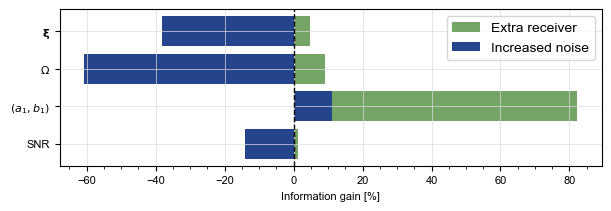

In [8]:
#__ Create figure and axes __
fig, ax = plt.subplots(figsize=(6,2), facecolor='white', layout='constrained')

#__ Format __
ax.set_xlabel("Information gain [%]", fontsize=small)
ax.xaxis.set_major_locator(ticker.MultipleLocator(20))
ax.xaxis.set_minor_locator(ticker.MultipleLocator(5))
ax.tick_params(labelsize=small)
ax.grid(color='gainsboro', linewidth=0.5)

#__ Labels __
y      = np.arange(4)[::-1]
labels = [r"$\mathbf{\xi}$", r"$\Omega$", r"$\left(a_1, b_1\right)$", r"SNR"]
ax.set_yticks(y, labels)

#__ Plot information gain __
ax.barh(y, rel_IG_rec, color=theme[1], label="Extra receiver", zorder=1)
ax.barh(y, rel_IG_noisy, color=theme[2], label="Increased noise", zorder=1)

#__ Plot neutral __
ax.axvline(0, c='k', ls='--', lw=1.0, zorder=2)

#__ Legend __
ax.legend(fontsize=large)

#__ Show figure __
fig.show()